# Best Practices: PEP 8, Docstrings & Clean Code

Code is read much more often than it is written. **Clean code** is code that another developer (or you, in six months) can understand and change safely. This lesson collects the conventions that the Python community uses.

**After this lesson you can:**

1. Apply the PEP 8 naming and layout rules.
2. Write docstrings in the Google style.
3. Refactor a long function into small, clear functions.
4. Organise a project folder and handle configuration and secrets safely.

## 1. PEP 8 Naming

**PEP 8** is the official style guide for Python code.

| Kind | Convention | Example |
| :--- | :--- | :--- |
| variable, function, method, module | `snake_case` | `total_price`, `load_data()` |
| class | `PascalCase` | `CustomerOrder` |
| constant | `UPPER_SNAKE_CASE` | `MAX_RETRIES = 3` |
| internal (not public) | leading underscore | `_cache`, `_parse_row()` |
| type variable | short `PascalCase` | `T`, `KeyT` |

Good names say **what** a value is (`days_since_signup`), not **how** it is stored (`int_list2`). Boolean names read like a question: `is_active`, `has_discount`.

## 2. Docstrings

A **docstring** is a string literal as the first statement of a module, class or function. Tools (`help()`, IDEs, documentation generators) read it. The Google style is easy to read:

In [1]:
def moving_average(values: list[float], window: int = 3) -> list[float]:
    """Compute the simple moving average of a sequence.

    Args:
        values: The input numbers, in time order.
        window: The number of points in each average. Must be at least 1.

    Returns:
        A list with ``len(values) - window + 1`` averages.

    Raises:
        ValueError: If ``window`` is smaller than 1 or larger than ``len(values)``.

    Example:
        >>> moving_average([1, 2, 3, 4], window=2)
        [1.5, 2.5, 3.5]
    """
    if not 1 <= window <= len(values):
        raise ValueError(f"window must be between 1 and {len(values)}, got {window}")
    return [sum(values[i:i + window]) / window for i in range(len(values) - window + 1)]

import doctest
print(doctest.testmod(verbose=False))      # runs the example in the docstring as a test
help(moving_average)

TestResults(failed=0, attempted=1)
Help on function moving_average in module __main__:

moving_average(values: list[float], window: int = 3) -> list[float]
    Compute the simple moving average of a sequence.

    Args:
        values: The input numbers, in time order.
        window: The number of points in each average. Must be at least 1.

    Returns:
        A list with ``len(values) - window + 1`` averages.

    Raises:
        ValueError: If ``window`` is smaller than 1 or larger than ``len(values)``.

    Example:
        >>> moving_average([1, 2, 3, 4], window=2)
        [1.5, 2.5, 3.5]



The `Example` section is also a test: `doctest` runs it and compares the output.

## 3. Refactoring a Long Function

The function below works, but it has several problems: it does four jobs, it uses unclear names, it hard-codes values and it prints instead of returning. This is a common shape for notebook code.

In [2]:
def process(d):
    r = []
    for x in d:
        if x["s"] == "active" and x["a"] > 0:
            v = x["a"] * 1.2
            if x["c"] == "TR":
                v = v * 0.9
            r.append({"id": x["id"], "v": round(v, 2)})
    t = 0
    for i in r:
        t += i["v"]
    print("total", t)
    return r

orders = [
    {"id": 1, "s": "active", "a": 100, "c": "TR"},
    {"id": 2, "s": "cancelled", "a": 50, "c": "DE"},
    {"id": 3, "s": "active", "a": 80, "c": "DE"},
]
before = process(orders)

total 204.0


In [3]:
from dataclasses import dataclass

VAT_RATE = 0.20
COUNTRY_DISCOUNT = {"TR": 0.10}

@dataclass(frozen=True)
class Order:
    order_id: int
    status: str
    net_amount: float
    country: str

def is_billable(order: Order) -> bool:
    """An order is billable if it is active and has a positive amount."""
    return order.status == "active" and order.net_amount > 0

def gross_amount(order: Order) -> float:
    """Net amount plus VAT, minus the country discount."""
    discount = COUNTRY_DISCOUNT.get(order.country, 0.0)
    return round(order.net_amount * (1 + VAT_RATE) * (1 - discount), 2)

def invoice_lines(orders: list[Order]) -> dict[int, float]:
    """Map the id of each billable order to its gross amount."""
    return {o.order_id: gross_amount(o) for o in orders if is_billable(o)}

typed_orders = [Order(o["id"], o["s"], o["a"], o["c"]) for o in orders]
after = invoice_lines(typed_orders)
print(after, "| total:", round(sum(after.values()), 2))
assert after == {line["id"]: line["v"] for line in before}      # same result as before

{1: 108.0, 3: 96.0} | total: 204.0


The refactored version gives the same result, but:

- every function has **one job** and a name that says what it does,
- the **business rules** (VAT, discounts) are named constants in one place,
- the data has a **type** (`Order`), so a typo such as `o.ammount` fails immediately,
- the functions **return** values instead of printing, so they are easy to test.

## 4. Measure Complexity

**Cyclomatic complexity** counts the independent paths through a function (roughly: 1 + the number of `if`, `for`, `while`, `and`, `or`, `except`). Functions with a complexity above 10 are hard to test. The cell measures it with the standard `ast` module.

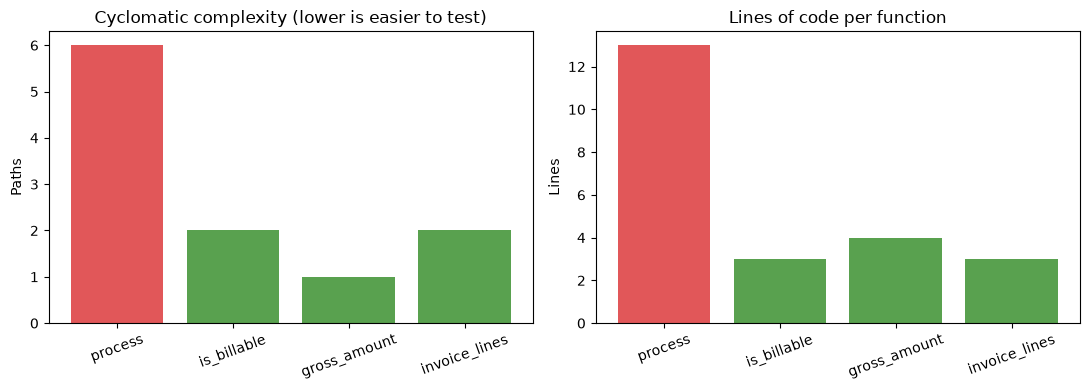

{'process': 6, 'is_billable': 2, 'gross_amount': 1, 'invoice_lines': 2}


In [4]:
import ast
import inspect

import matplotlib.pyplot as plt

def complexity(func) -> int:
    tree = ast.parse(inspect.getsource(func))
    branches = (ast.If, ast.For, ast.While, ast.ExceptHandler, ast.BoolOp, ast.IfExp, ast.comprehension)
    return 1 + sum(isinstance(node, branches) for node in ast.walk(tree))

def length(func) -> int:
    return len(inspect.getsource(func).splitlines())

funcs = [process, is_billable, gross_amount, invoice_lines]
names = [f.__name__ for f in funcs]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#E15759"] + ["#59A14F"] * 3
ax1.bar(names, [complexity(f) for f in funcs], color=colors)
ax1.set(title="Cyclomatic complexity (lower is easier to test)", ylabel="Paths")
ax2.bar(names, [length(f) for f in funcs], color=colors)
ax2.set(title="Lines of code per function", ylabel="Lines")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print({f.__name__: complexity(f) for f in funcs})

## 5. Project Layout, Configuration and Secrets

A typical layout for a Python project (the **src layout**):

```
my-project/
├── pyproject.toml        # metadata, dependencies, tool settings
├── uv.lock               # exact versions
├── README.md
├── .env.example          # names of required settings, no real values
├── src/my_project/       # the importable package
│   ├── __init__.py
│   ├── config.py         # reads settings from environment variables
│   └── ...
├── tests/                # pytest tests (Lesson 04)
└── notebooks/            # exploration only; move reusable code to src/
```

Rules for **configuration and secrets**:

1. Read settings from **environment variables**, not from constants in code.
2. Never commit passwords, API keys or tokens. Put `.env` in `.gitignore` and commit only `.env.example`.
3. If a secret reaches Git, **rotate it** (create a new one). Deleting the commit is not enough: the history keeps it.

*Insight: Clean code is not about style alone. Small functions with clear names, typed data and named constants make bugs visible and make tests easy to write. Let Ruff (Lesson 02) handle formatting, and spend review time on names and structure.*

## Real-World Use Case or Analogy

Clean code is like a **well-organised kitchen in a restaurant**. Every ingredient has a labelled container (good names), every station does one job (small functions), and the recipes are written down (docstrings). A new cook can start work on the first day. In a messy kitchen, only the person who arranged it can find anything, and every change is risky.

Companies enforce these rules with code review, linters and templates for new repositories. Data teams follow the same path: exploratory notebook code moves into a `src/` package with docstrings and tests before it runs in production.